In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Load dataset from your local file path
file_path = r"C:\Users\ngosa\Desktop\GITHUB ROADMAP\synthetic hotel dataset\Hotel_Dataset_2025.csv"
df = pd.read_csv(file_path, parse_dates=["Date", "Booking Date", "Departure Date"])

# 2. Define room inventory and illustrative cost model assumptions
ROOMS = {"City Hotel": 60, "Resort Hotel": 66}
PORTFOLIO_ROOMS = sum(ROOMS.values())  # 126 rooms

MARGIN = {
    "Rooms": 0.72,
    "F&B": 0.30,
    "Spa": 0.35,
    "Meetings": 0.45,
    "Other": 0.50
}
UNDISTRIBUTED = 0.30

# 3. Filter stayed bookings and expand to individual stay-nights
stays = df[df["Cancellation Status"] == "Not Cancelled"].copy()

nights = stays.loc[stays.index.repeat(stays["LOS"])].copy()
nights["Night"] = nights["Date"] + pd.to_timedelta(
    nights.groupby(level=0).cumcount(), unit="D"
)

# Drop stay-nights extending into 2026
nights = nights[nights["Night"] <= "2025-12-31"].copy()
nights["Night_Month"] = nights["Night"].dt.month
nights["Night_Month_Name"] = nights["Night"].dt.strftime("%b")

# 4. Spread revenue evenly across each stay's LOS and flag paid nights
rev_cols = [
    "Room Revenue", "Restaurant Revenue", "Bar Revenue",
    "Spa Revenue", "Meeting/Event Revenue", "Other Revenue", "Total Revenue"
]
for col in rev_cols:
    nights[col] = nights[col] / nights["LOS"]

nights["Paid"] = (nights["ADR"] > 0).astype(int)

# Verification check
print(f"Total bookings loaded: {len(df):,}")
print(f"Stayed bookings:       {len(stays):,}")
print(f"Cancelled bookings:    {(df['Cancellation Status'] == 'Cancelled').sum():,} ({(df['Cancellation Status'] == 'Cancelled').mean()*100:.1f}%)")
print(f"2025 Stay-nights:      {len(nights):,} (Paid: {nights['Paid'].sum():,})")

Total bookings loaded: 15,500
Stayed bookings:       11,720
Cancelled bookings:    3,780 (24.4%)
2025 Stay-nights:      30,677 (Paid: 30,557)


In [2]:
# --- SECTION 01: EXECUTIVE SUMMARY ---

def compute_headline_kpis(nights_df, rooms_count):
    avail = rooms_count * 365
    sold = len(nights_df)
    paid = nights_df["Paid"].sum()
    
    room_rev = nights_df["Room Revenue"].sum()
    fb_rev = (nights_df["Restaurant Revenue"] + nights_df["Bar Revenue"]).sum()
    spa_rev = nights_df["Spa Revenue"].sum()
    mtg_rev = nights_df["Meeting/Event Revenue"].sum()
    oth_rev = nights_df["Other Revenue"].sum()
    tot_rev = room_rev + fb_rev + spa_rev + mtg_rev + oth_rev
    
    dept_profit = (
        room_rev * MARGIN["Rooms"]
        + fb_rev * MARGIN["F&B"]
        + spa_rev * MARGIN["Spa"]
        + mtg_rev * MARGIN["Meetings"]
        + oth_rev * MARGIN["Other"]
    )
    gop = dept_profit - (UNDISTRIBUTED * tot_rev)
    
    return {
        "Occupancy %": round(sold / avail * 100, 1),
        "ADR (€)": round(room_rev / paid, 1),
        "RevPAR (€)": round(room_rev / avail, 1),
        "TRevPAR (€)": round(tot_rev / avail, 1),
        "GOPPAR (€)": round(gop / avail, 1),
        "Ancillary Share %": round((tot_rev - room_rev) / tot_rev * 100, 1)
    }

# 1. Headline KPI Table (Portfolio, City, Resort)
exec_summary = pd.DataFrame({
    "Portfolio": compute_headline_kpis(nights, PORTFOLIO_ROOMS),
    "City Hotel": compute_headline_kpis(nights[nights["Hotel"] == "City Hotel"], ROOMS["City Hotel"]),
    "Resort Hotel": compute_headline_kpis(nights[nights["Hotel"] == "Resort Hotel"], ROOMS["Resort Hotel"]),
})
print("=== 01. EXECUTIVE SUMMARY HEADLINE KPIs ===")
print(exec_summary)

# 2. Seasonality Peaks & Troughs Check
days_in_month = pd.Series(pd.date_range("2025-01-01", "2025-12-31")).dt.month.value_counts().sort_index()
monthly_occ = (
    nights.groupby(["Hotel", "Night_Month"]).size().unstack(0)
    .div(days_in_month, axis=0)
)
monthly_occ["City Hotel"] = (monthly_occ["City Hotel"] / ROOMS["City Hotel"] * 100).round(0)
monthly_occ["Resort Hotel"] = (monthly_occ["Resort Hotel"] / ROOMS["Resort Hotel"] * 100).round(0)
monthly_occ.index = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

print("\n=== MONTHLY OCCUPANCY (%) CHECK ===")
print(monthly_occ.T)

# 3. Cancellation Rates Check
overall_cancel = (df["Cancellation Status"] == "Cancelled").mean() * 100
channel_cancel = (
    df.groupby("Booking Channel")["Cancellation Status"]
    .apply(lambda s: (s == "Cancelled").mean() * 100)
    .round(1)
)
print(f"\nOverall Cancellation Rate: {overall_cancel:.1f}%")
print(f"OTA Cancellation Rate:     {channel_cancel['Online Travel Agency']:.1f}%")
print(f"Direct Website Cancel:     {channel_cancel['Direct Website']:.1f}%")

=== 01. EXECUTIVE SUMMARY HEADLINE KPIs ===
                   Portfolio  City Hotel  Resort Hotel
Occupancy %             66.7        65.8          67.5
ADR (€)                123.7       113.5         132.8
RevPAR (€)              82.2        74.3          89.4
TRevPAR (€)            128.3       101.2         153.0
GOPPAR (€)              36.3        33.0          39.3
Ancillary Share %       35.9        26.5          41.6

=== MONTHLY OCCUPANCY (%) CHECK ===
               Jan   Feb   Mar   Apr   May   Jun   Jul   Aug   Sep   Oct  \
Hotel                                                                      
City Hotel    53.0  56.0  80.0  61.0  74.0  72.0  66.0  58.0  72.0  77.0   
Resort Hotel  41.0  44.0  54.0  73.0  76.0  82.0  89.0  88.0  81.0  66.0   

               Nov   Dec  
Hotel                     
City Hotel    77.0  45.0  
Resort Hotel  42.0  71.0  

Overall Cancellation Rate: 24.4%
OTA Cancellation Rate:     37.8%
Direct Website Cancel:     21.9%


=== 02. ROOMS KPIs SUMMARY BY HOTEL ===
              Available Nights  Sold Nights  Paid Nights  Occupancy %  \
Hotel                                                                   
City Hotel               21900        14414        14342         65.8   
Resort Hotel             24090        16263        16215         67.5   

              ADR (€)  RevPAR (€)  Room Revenue (€M)  
Hotel                                                 
City Hotel      113.5        74.3               1.63  
Resort Hotel    132.8        89.4               2.15  

Total Room Revenue: €3.78M (Resort share: 57%)

=== MONTHLY OCCUPANCY (%) ===
               Jan   Feb   Mar   Apr   May   Jun   Jul   Aug   Sep   Oct  \
City Hotel    52.7  56.4  80.1  60.9  73.9  71.8  65.7  57.6  71.6  77.0   
Resort Hotel  41.3  44.5  54.3  73.5  76.1  81.6  88.6  87.9  81.4  65.9   

               Nov   Dec  
City Hotel    77.1  44.6  
Resort Hotel  41.8  71.4  

=== MONTHLY REVPAR (€) ===
               Jan   Feb   Mar

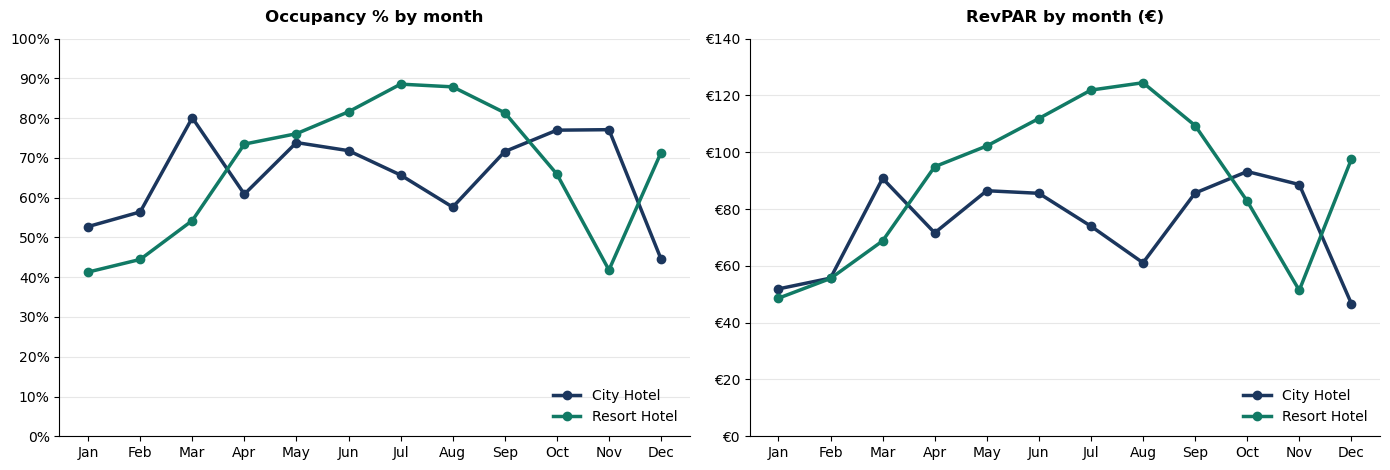

In [3]:
# --- SECTION 02: ROOMS KPIs ---

# 1. Days in each month of 2025
days_in_month = (
    pd.Series(pd.date_range("2025-01-01", "2025-12-31"))
    .dt.month.value_counts()
    .sort_index()
)
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

# 2. Annual Rooms KPI Summary by Hotel
rooms_summary = []
for hotel in ["City Hotel", "Resort Hotel"]:
    n = nights[nights["Hotel"] == hotel]
    avail = ROOMS[hotel] * 365
    sold = len(n)
    paid = n["Paid"].sum()
    rev = n["Room Revenue"].sum()
    rooms_summary.append({
        "Hotel": hotel,
        "Available Nights": avail,
        "Sold Nights": sold,
        "Paid Nights": paid,
        "Occupancy %": round(sold / avail * 100, 1),
        "ADR (€)": round(rev / paid, 1),
        "RevPAR (€)": round(rev / avail, 1),
        "Room Revenue (€M)": round(rev / 1e6, 2)
    })

rooms_summary_df = pd.DataFrame(rooms_summary).set_index("Hotel")
total_room_rev = nights["Room Revenue"].sum()
resort_share = nights[nights["Hotel"] == "Resort Hotel"]["Room Revenue"].sum() / total_room_rev * 100

print("=== 02. ROOMS KPIs SUMMARY BY HOTEL ===")
print(rooms_summary_df)
print(f"\nTotal Room Revenue: €{total_room_rev / 1e6:.2f}M (Resort share: {resort_share:.0f}%)")

# 3. Monthly Occupancy % and RevPAR (€) Pivot Tables
m_sold = nights.groupby(["Night_Month", "Hotel"]).size().unstack()
m_rev = nights.groupby(["Night_Month", "Hotel"])["Room Revenue"].sum().unstack()

m_avail_city = days_in_month * ROOMS["City Hotel"]
m_avail_resort = days_in_month * ROOMS["Resort Hotel"]

m_occ = pd.DataFrame({
    "City Hotel": m_sold["City Hotel"] / m_avail_city * 100,
    "Resort Hotel": m_sold["Resort Hotel"] / m_avail_resort * 100
})
m_occ.index = month_names

m_revpar = pd.DataFrame({
    "City Hotel": m_rev["City Hotel"] / m_avail_city,
    "Resort Hotel": m_rev["Resort Hotel"] / m_avail_resort
})
m_revpar.index = month_names

print("\n=== MONTHLY OCCUPANCY (%) ===")
print(m_occ.round(1).T)

print("\n=== MONTHLY REVPAR (€) ===")
print(m_revpar.round(1).T)

# 4. Plot Charts: Occupancy % by month & RevPAR by month (€)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

colors = {"City Hotel": "#1B365D", "Resort Hotel": "#117A65"}

# Chart 1: Occupancy % by month
for hotel in ["City Hotel", "Resort Hotel"]:
    axes[0].plot(
        m_occ.index, m_occ[hotel],
        marker="o", linewidth=2.5, markersize=6,
        color=colors[hotel], label=hotel
    )
axes[0].set_title("Occupancy % by month", fontsize=12, fontweight="bold", pad=12)
axes[0].set_ylim(0, 100)
axes[0].set_yticks(range(0, 101, 10))
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{int(y)}%"))
axes[0].grid(axis="y", linestyle="-", alpha=0.3)
axes[0].spines["top"].set_visible(False)
axes[0].spines["right"].set_visible(False)
axes[0].legend(frameon=False, loc="lower right")

# Chart 2: RevPAR by month (€)
for hotel in ["City Hotel", "Resort Hotel"]:
    axes[1].plot(
        m_revpar.index, m_revpar[hotel],
        marker="o", linewidth=2.5, markersize=6,
        color=colors[hotel], label=hotel
    )
axes[1].set_title("RevPAR by month (€)", fontsize=12, fontweight="bold", pad=12)
axes[1].set_ylim(0, 140)
axes[1].set_yticks(range(0, 141, 20))
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"€{int(y)}"))
axes[1].grid(axis="y", linestyle="-", alpha=0.3)
axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)
axes[1].legend(frameon=False, loc="lower right")

plt.tight_layout()
plt.show()

=== 03. ROOM TYPE PERFORMANCE TABLE ===
       Hotel          Room Type  Rooms  Available Nights  Sold Nights  Occupancy %  ADR (€)  RevPAR (€)
  City Hotel      Standard Room     26              9490         6028         63.5     88.0        55.0
  City Hotel      Superior Room     15              5475         4318         78.9    111.0        87.0
  City Hotel        Deluxe Room     10              3650         2545         69.7    133.0        92.0
  City Hotel       Junior Suite      6              2190         1076         49.1    171.0        83.0
  City Hotel              Suite      3              1095          447         40.8    240.0        98.0
Resort Hotel      Standard Room     24              8760         5722         65.3    100.0        65.0
Resort Hotel Deluxe Garden View     18              6570         4634         70.5    128.0        90.0
Resort Hotel   Deluxe Pool View     13              4745         3086         65.0    152.0        98.0
Resort Hotel        Fami

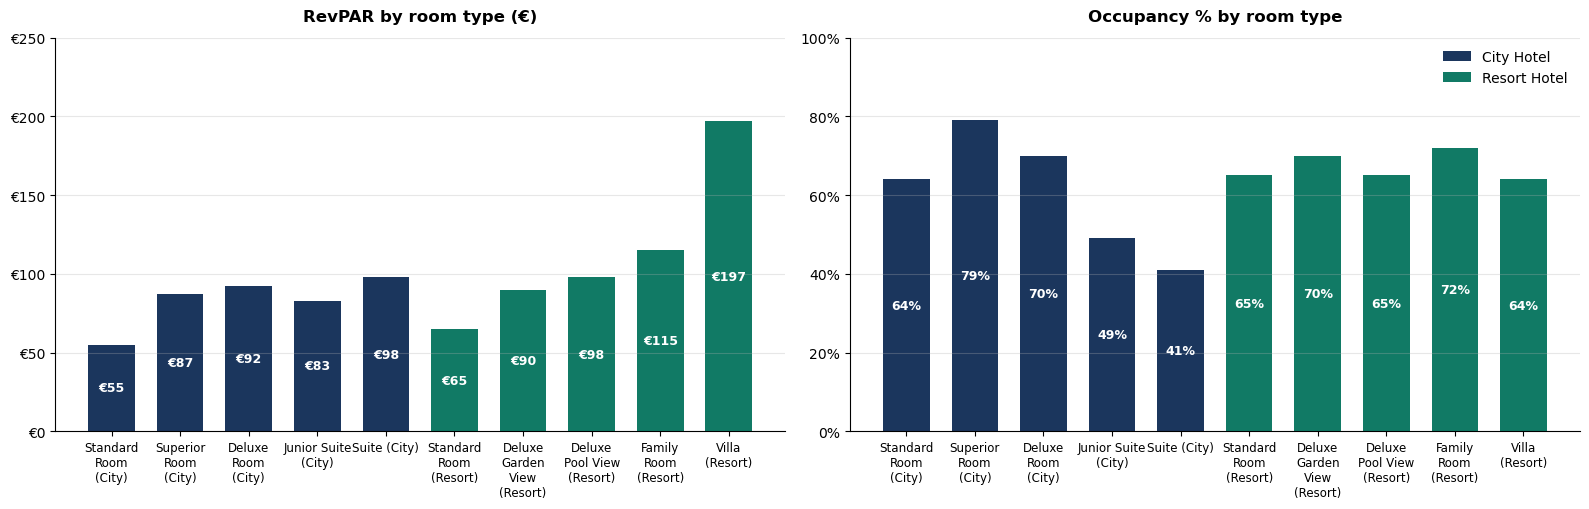

In [4]:
# --- SECTION 03: ROOM TYPE PERFORMANCE ---

# 1. Extract room inventory per Hotel and Room Type
rt_inv = df[["Hotel", "Room Type", "Available Rooms"]].drop_duplicates()

room_order = [
    ("City Hotel", "Standard Room", "Standard\nRoom\n(City)"),
    ("City Hotel", "Superior Room", "Superior\nRoom\n(City)"),
    ("City Hotel", "Deluxe Room", "Deluxe\nRoom\n(City)"),
    ("City Hotel", "Junior Suite", "Junior Suite\n(City)"),
    ("City Hotel", "Suite", "Suite (City)"),
    ("Resort Hotel", "Standard Room", "Standard\nRoom\n(Resort)"),
    ("Resort Hotel", "Deluxe Garden View", "Deluxe\nGarden\nView\n(Resort)"),
    ("Resort Hotel", "Deluxe Pool View", "Deluxe\nPool View\n(Resort)"),
    ("Resort Hotel", "Family Room", "Family\nRoom\n(Resort)"),
    ("Resort Hotel", "Villa", "Villa\n(Resort)")
]

# 2. Compute Occupancy %, ADR (€), and RevPAR (€) for each room type
rt_rows = []
for hotel, rtype, label in room_order:
    rooms_cnt = rt_inv[(rt_inv["Hotel"] == hotel) & (rt_inv["Room Type"] == rtype)]["Available Rooms"].iloc[0]
    avail = rooms_cnt * 365
    n = nights[(nights["Hotel"] == hotel) & (nights["Room Type"] == rtype)]
    
    sold = len(n)
    paid = n["Paid"].sum()
    rev = n["Room Revenue"].sum()
    
    rt_rows.append({
        "Hotel": hotel,
        "Room Type": rtype,
        "Label": label,
        "Rooms": rooms_cnt,
        "Available Nights": avail,
        "Sold Nights": sold,
        "Occupancy %": round(sold / avail * 100, 1),
        "ADR (€)": round(rev / paid, 0),
        "RevPAR (€)": round(rev / avail, 0),
        "Room Revenue (€)": round(rev, 2)
    })

rt_df = pd.DataFrame(rt_rows)

print("=== 03. ROOM TYPE PERFORMANCE TABLE ===")
print(rt_df[["Hotel", "Room Type", "Rooms", "Available Nights", "Sold Nights", "Occupancy %", "ADR (€)", "RevPAR (€)"]].to_string(index=False))

# 3. Plot Side-by-Side Bar Charts: RevPAR by room type (€) & Occupancy % by room type
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))
bar_colors = ["#1B365D" if h == "City Hotel" else "#117A65" for h in rt_df["Hotel"]]
x = np.arange(len(rt_df))

# Chart 1: RevPAR by room type (€)
bars1 = axes[0].bar(x, rt_df["RevPAR (€)"], color=bar_colors, width=0.68)
axes[0].set_title("RevPAR by room type (€)", fontsize=12, fontweight="bold", pad=12)
axes[0].set_xticks(x)
axes[0].set_xticklabels(rt_df["Label"], fontsize=8.5)
axes[0].set_ylim(0, 250)
axes[0].set_yticks(range(0, 251, 50))
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"€{int(y)}"))
axes[0].grid(axis="y", linestyle="-", alpha=0.3)
axes[0].spines["top"].set_visible(False)
axes[0].spines["right"].set_visible(False)

for bar, val in zip(bars1, rt_df["RevPAR (€)"]):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2, val / 2,
        f"€{int(val)}", ha="center", va="center",
        color="white", fontsize=9, fontweight="bold"
    )

# Chart 2: Occupancy % by room type
occ_rounded = rt_df["Occupancy %"].round(0)
bars2 = axes[1].bar(x, occ_rounded, color=bar_colors, width=0.68)
axes[1].set_title("Occupancy % by room type", fontsize=12, fontweight="bold", pad=12)
axes[1].set_xticks(x)
axes[1].set_xticklabels(rt_df["Label"], fontsize=8.5)
axes[1].set_ylim(0, 100)
axes[1].set_yticks(range(0, 101, 20))
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{int(y)}%"))
axes[1].grid(axis="y", linestyle="-", alpha=0.3)
axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)

for bar, val in zip(bars2, occ_rounded):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2, val / 2,
        f"{int(val)}%", ha="center", va="center",
        color="white", fontsize=9, fontweight="bold"
    )

# Legend for both charts
from matplotlib.patches import Patch
legend_handles = [
    Patch(facecolor="#1B365D", label="City Hotel"),
    Patch(facecolor="#117A65", label="Resort Hotel")
]
axes[1].legend(handles=legend_handles, frameon=False, loc="upper right")

plt.tight_layout()
plt.show()

=== 04A. BOOKING PACE BY HOTEL (% ON THE BOOKS) ===
Days Before Arrival   180   150   120   90    60    45    30    21    14   \
City Hotel            5.8   8.3  12.5  18.7  30.2  38.0  48.3  55.6  64.4   
Resort Hotel         10.7  14.5  20.5  32.3  48.2  57.0  68.8  77.3  84.1   
Portfolio             8.4  11.6  16.8  25.9  39.8  48.1  59.2  67.1  74.9   

Days Before Arrival   7     3      0    
City Hotel           78.2  88.8  100.0  
Resort Hotel         91.2  94.7  100.0  
Portfolio            85.1  91.9  100.0  

=== 04B. BOOKING PACE BY MARKET SEGMENT (% ON THE BOOKS) ===
Days Before Arrival   180   150   120   90    60    45     30     21     14   \
Leisure               6.8   9.3  14.1  21.5  34.3  44.6   58.9   70.1   79.8   
Business Transient    0.1   0.1   0.1   0.4   1.1   2.3    5.9   10.0   19.3   
Corporate Contract    0.3   0.3   0.7   1.7   4.0   8.0   18.0   30.7   47.2   
Group                20.1  26.3  34.4  58.0  86.4  93.4  100.0  100.0  100.0   
Tour Operator

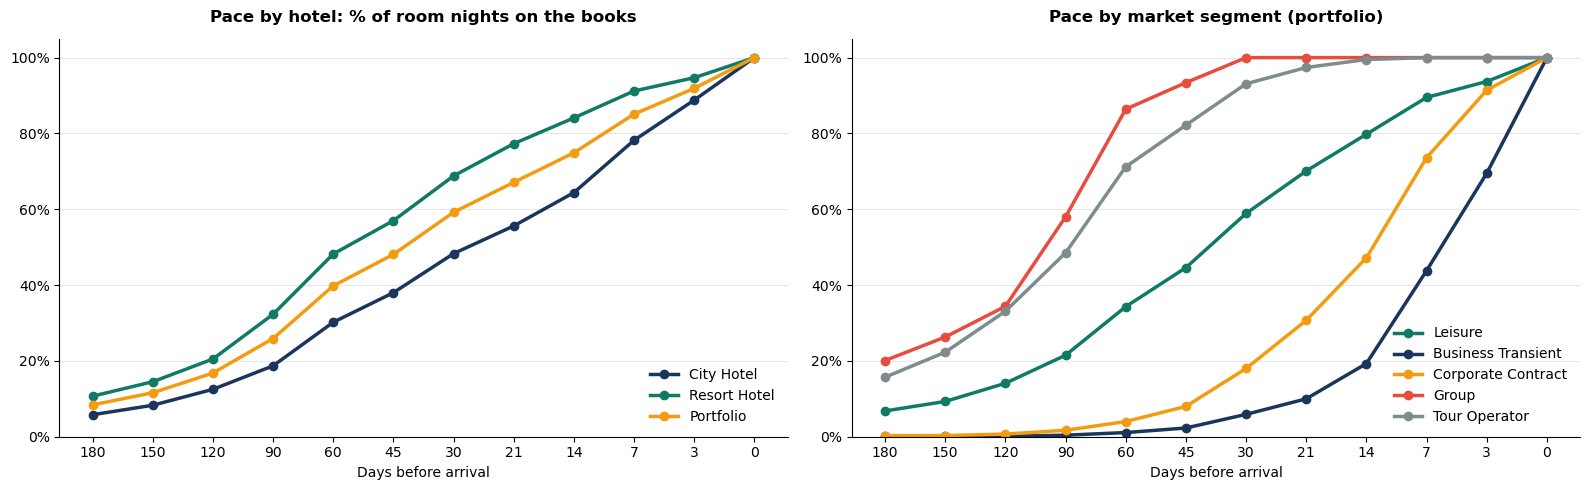

In [5]:
# --- SECTION 04: BOOKING PACE ---

days_grid = [180, 150, 120, 90, 60, 45, 30, 21, 14, 7, 3, 0]

def compute_pace_curve(data, grid):
    total_los = data["LOS"].sum()
    return [
        round(data.loc[data["Lead Time"] >= d, "LOS"].sum() / total_los * 100, 1)
        for d in grid
    ]

# 1. Pace by Hotel & Portfolio Pivot Table
pace_hotel = pd.DataFrame({
    "City Hotel": compute_pace_curve(stays[stays["Hotel"] == "City Hotel"], days_grid),
    "Resort Hotel": compute_pace_curve(stays[stays["Hotel"] == "Resort Hotel"], days_grid),
    "Portfolio": compute_pace_curve(stays, days_grid)
}, index=days_grid).T
pace_hotel.columns.name = "Days Before Arrival"

print("=== 04A. BOOKING PACE BY HOTEL (% ON THE BOOKS) ===")
print(pace_hotel)

# 2. Pace by Market Segment (Portfolio) Pivot Table
segments_order = [
    "Leisure", "Business Transient", "Corporate Contract", "Group", "Tour Operator"
]
pace_segment = pd.DataFrame({
    seg: compute_pace_curve(stays[stays["Market Segment"] == seg], days_grid)
    for seg in segments_order
}, index=days_grid).T
pace_segment.columns.name = "Days Before Arrival"

print("\n=== 04B. BOOKING PACE BY MARKET SEGMENT (% ON THE BOOKS) ===")
print(pace_segment)

# 3. Plot Side-by-Side Booking Pace Line Charts
fig, axes = plt.subplots(1, 2, figsize=(16, 5.0))
x_labels = [str(d) for d in days_grid]

# Chart 1: Pace by hotel
hotel_colors = {
    "City Hotel": "#1B365D",
    "Resort Hotel": "#117A65",
    "Portfolio": "#F39C12"
}
for label, color in hotel_colors.items():
    axes[0].plot(
        x_labels, pace_hotel.loc[label],
        marker="o", linewidth=2.5, markersize=6,
        color=color, label=label
    )
axes[0].set_title("Pace by hotel: % of room nights on the books", fontsize=12, fontweight="bold", pad=12)
axes[0].set_xlabel("Days before arrival", fontsize=10)
axes[0].set_ylim(0, 105)
axes[0].set_yticks(range(0, 101, 20))
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{int(y)}%"))
axes[0].grid(axis="y", linestyle="-", alpha=0.3)
axes[0].spines["top"].set_visible(False)
axes[0].spines["right"].set_visible(False)
axes[0].legend(frameon=False, loc="lower right")

# Chart 2: Pace by market segment (portfolio)
seg_colors = {
    "Leisure": "#117A65",
    "Business Transient": "#1B365D",
    "Corporate Contract": "#F39C12",
    "Group": "#E74C3C",
    "Tour Operator": "#7F8C8D"
}
for seg, color in seg_colors.items():
    axes[1].plot(
        x_labels, pace_segment.loc[seg],
        marker="o", linewidth=2.5, markersize=6,
        color=color, label=seg
    )
axes[1].set_title("Pace by market segment (portfolio)", fontsize=12, fontweight="bold", pad=12)
axes[1].set_xlabel("Days before arrival", fontsize=10)
axes[1].set_ylim(0, 105)
axes[1].set_yticks(range(0, 101, 20))
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{int(y)}%"))
axes[1].grid(axis="y", linestyle="-", alpha=0.3)
axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)
axes[1].legend(frameon=False, loc="lower right")

plt.tight_layout()
plt.show()

=== 05A. PICKUP BY BOOKING WINDOW (% OF ROOM NIGHTS) ===
           City Hotel  Resort Hotel  Portfolio
0 to 7           24.2           9.7       16.5
8 to 14          12.9           7.1        9.8
15 to 30         15.6          15.1       15.3
31 to 60         17.6          20.9       19.3
61 to 90         11.3          15.3       13.4
91 to 180        12.8          21.3       17.3
181+              5.7          10.6        8.3

Final 30 days pickup -> City: 52.6% | Resort: 31.9% | Portfolio: 41.6% (>30 days: 58.4%)

=== 05B. % OF ROOM NIGHTS BOOKED WITHIN 30 DAYS BY ARRIVAL MONTH ===
               Jan   Feb   Mar   Apr   May   Jun   Jul   Aug   Sep   Oct  \
Hotel                                                                      
City Hotel    51.0  49.8  50.6  57.5  51.4  54.1  53.6  54.3  58.3  50.2   
Resort Hotel  32.9  34.7  35.4  27.8  31.7  34.4  27.2  31.0  28.3  29.4   

               Nov   Dec  
Hotel                     
City Hotel    46.4  57.4  
Resort Hotel  40.2  3

C:\Users\ngosa\AppData\Local\Temp\ipykernel_34144\714096042.py:43: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: round(g.loc[g["Lead Time"] <= 30, "LOS"].sum() / g["LOS"].sum() * 100, 1))


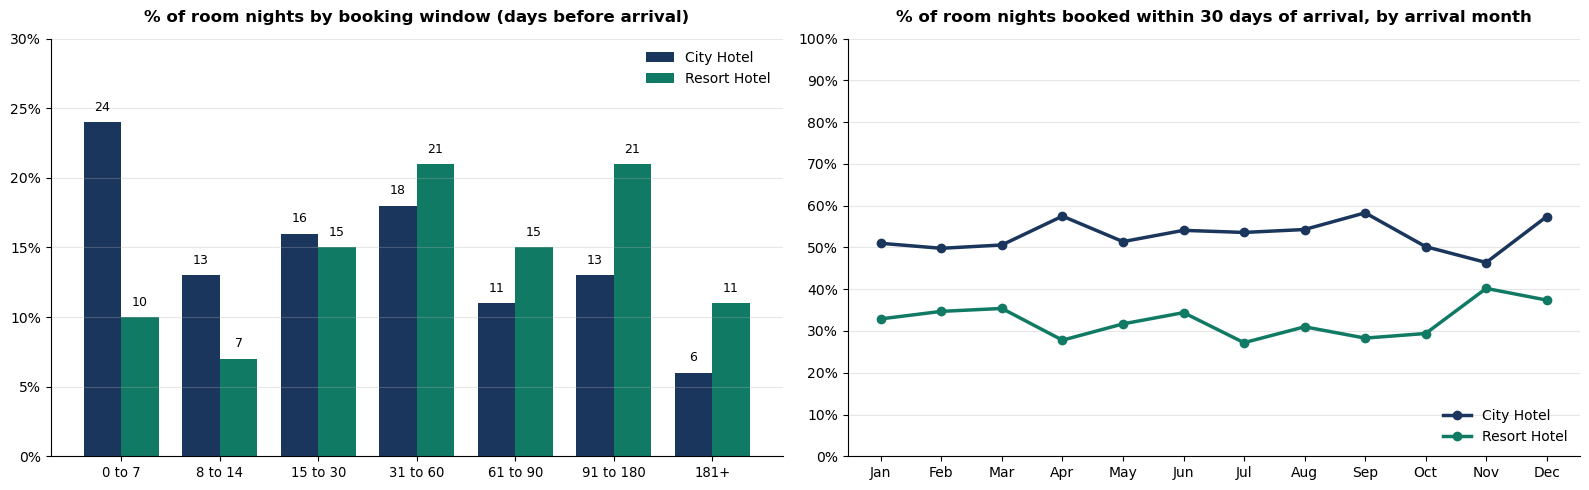

In [6]:
# --- SECTION 05: PICKUP ---

windows = [
    ("0 to 7", 0, 7),
    ("8 to 14", 8, 14),
    ("15 to 30", 15, 30),
    ("31 to 60", 31, 60),
    ("61 to 90", 61, 90),
    ("91 to 180", 91, 180),
    ("181+", 181, 9999)
]

def compute_pickup_windows(data, win_list):
    total_los = data["LOS"].sum()
    return {
        label: round(data.loc[data["Lead Time"].between(low, high), "LOS"].sum() / total_los * 100, 1)
        for label, low, high in win_list
    }

# 1. Pickup by Booking Window Pivot Table
pickup_df = pd.DataFrame({
    "City Hotel": compute_pickup_windows(stays[stays["Hotel"] == "City Hotel"], windows),
    "Resort Hotel": compute_pickup_windows(stays[stays["Hotel"] == "Resort Hotel"], windows),
    "Portfolio": compute_pickup_windows(stays, windows)
})

print("=== 05A. PICKUP BY BOOKING WINDOW (% OF ROOM NIGHTS) ===")
print(pickup_df)

# 2. Final 30-Day & >30-Day Summary Check
city_30 = stays[(stays["Hotel"] == "City Hotel") & (stays["Lead Time"] <= 30)]["LOS"].sum() / stays[stays["Hotel"] == "City Hotel"]["LOS"].sum() * 100
resort_30 = stays[(stays["Hotel"] == "Resort Hotel") & (stays["Lead Time"] <= 30)]["LOS"].sum() / stays[stays["Hotel"] == "Resort Hotel"]["LOS"].sum() * 100
port_30 = stays[stays["Lead Time"] <= 30]["LOS"].sum() / stays["LOS"].sum() * 100

print(f"\nFinal 30 days pickup -> City: {city_30:.1f}% | Resort: {resort_30:.1f}% | Portfolio: {port_30:.1f}% (>30 days: {100 - port_30:.1f}%)")

# 3. Monthly % Booked Within 30 Days of Arrival (by Arrival Month)
stays["Arrival_Month"] = stays["Date"].dt.month
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

monthly_pickup_30 = (
    stays.groupby(["Arrival_Month", "Hotel"])
    .apply(lambda g: round(g.loc[g["Lead Time"] <= 30, "LOS"].sum() / g["LOS"].sum() * 100, 1))
    .unstack()
)
monthly_pickup_30.index = month_names

print("\n=== 05B. % OF ROOM NIGHTS BOOKED WITHIN 30 DAYS BY ARRIVAL MONTH ===")
print(monthly_pickup_30.T)

# 4. Plot Side-by-Side Charts
fig, axes = plt.subplots(1, 2, figsize=(16, 5.0))
colors = {"City Hotel": "#1B365D", "Resort Hotel": "#117A65"}

# Chart 1: % of room nights by booking window (Grouped Bar Chart)
x = np.arange(len(pickup_df))
width = 0.38

city_vals = pickup_df["City Hotel"].round(0)
resort_vals = pickup_df["Resort Hotel"].round(0)

bars_c = axes[0].bar(x - width/2, city_vals, width, label="City Hotel", color=colors["City Hotel"])
bars_r = axes[0].bar(x + width/2, resort_vals, width, label="Resort Hotel", color=colors["Resort Hotel"])

axes[0].set_title("% of room nights by booking window (days before arrival)", fontsize=12, fontweight="bold", pad=12)
axes[0].set_xticks(x)
axes[0].set_xticklabels(pickup_df.index, fontsize=9.5)
axes[0].set_ylim(0, 30)
axes[0].set_yticks(range(0, 31, 5))
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{int(y)}%"))
axes[0].grid(axis="y", linestyle="-", alpha=0.3)
axes[0].spines["top"].set_visible(False)
axes[0].spines["right"].set_visible(False)
axes[0].legend(frameon=False, loc="upper right")

for bars in [bars_c, bars_r]:
    for bar in bars:
        h = bar.get_height()
        axes[0].text(
            bar.get_x() + bar.get_width() / 2, h + 0.6,
            f"{int(h)}", ha="center", va="bottom", fontsize=9
        )

# Chart 2: % of room nights booked within 30 days of arrival, by arrival month
for hotel in ["City Hotel", "Resort Hotel"]:
    axes[1].plot(
        monthly_pickup_30.index, monthly_pickup_30[hotel],
        marker="o", linewidth=2.5, markersize=6,
        color=colors[hotel], label=hotel
    )
axes[1].set_title("% of room nights booked within 30 days of arrival, by arrival month", fontsize=12, fontweight="bold", pad=12)
axes[1].set_ylim(0, 100)
axes[1].set_yticks(range(0, 101, 10))
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{int(y)}%"))
axes[1].grid(axis="y", linestyle="-", alpha=0.3)
axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)
axes[1].legend(frameon=False, loc="lower right")

plt.tight_layout()
plt.show()

=== 06. MARKET SEGMENT ANALYSIS TABLE (SLIDE 8) ===
           Segment Nights share  ADR Median lead Ancillary %  Room Rev Share %  Cancel Rate %  Rev/Room Night (€)
           Leisure        49.6% €138     36 days       36.7%              55.4           31.9               218.0
     Tour Operator        17.6% €100     88 days       41.1%              14.2           31.5               169.0
Business Transient        12.6% €130      5 days       19.9%              13.3           14.4               163.0
             Group        11.3% €101     94 days       47.3%               9.3           16.8               191.0
Corporate Contract         8.6% €112     12 days       23.8%               7.8            9.6               146.0
     Complimentary         0.4%  n/a      0 days        0.0%               0.0            0.0                 0.0


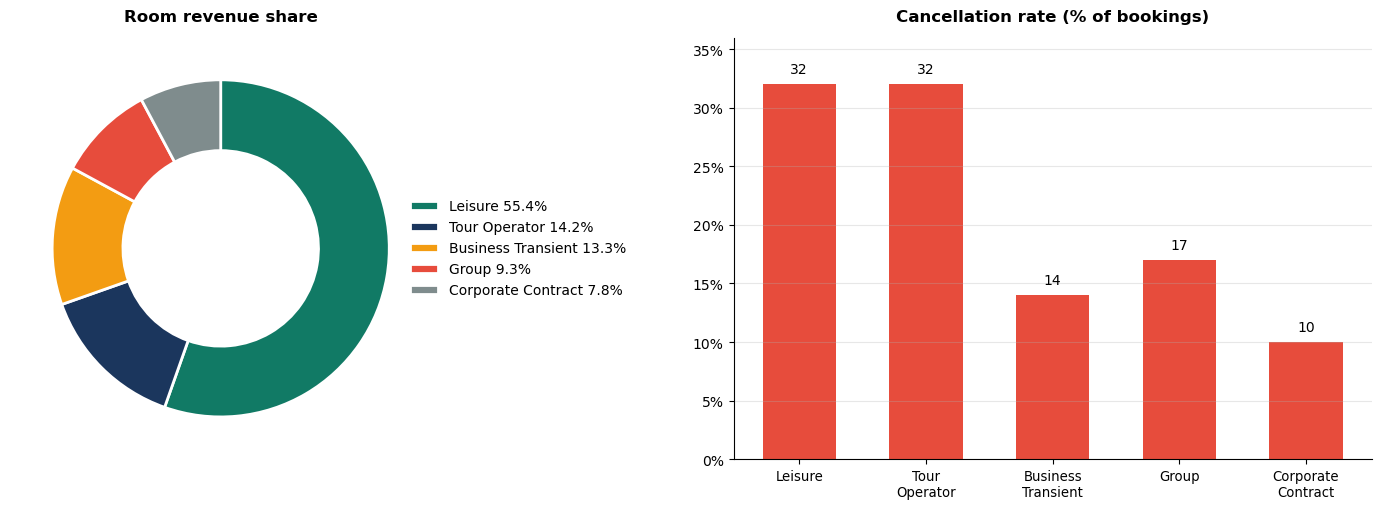

In [7]:
# --- SECTION 06: MARKET SEGMENT ANALYSIS ---

seg_order = [
    "Leisure", "Tour Operator", "Business Transient",
    "Group", "Corporate Contract", "Complimentary"
]

tot_room_rev = nights["Room Revenue"].sum()
tot_nights = len(nights)

seg_rows = []
for seg in seg_order:
    n_seg = nights[nights["Market Segment"] == seg]
    s_seg = stays[stays["Market Segment"] == seg]
    all_seg = df[df["Market Segment"] == seg]
    
    room_rev = n_seg["Room Revenue"].sum()
    tot_rev = n_seg["Total Revenue"].sum()
    paid_n = n_seg["Paid"].sum()
    
    seg_rows.append({
        "Segment": seg,
        "Room Rev Share %": round(room_rev / tot_room_rev * 100, 1),
        "Nights share": f"{len(n_seg) / tot_nights * 100:.1f}%",
        "ADR": f"€{room_rev / paid_n:.0f}" if paid_n > 0 else "n/a",
        "Cancel Rate %": round((all_seg["Cancellation Status"] == "Cancelled").mean() * 100, 1),
        "Median lead": f"{int(s_seg['Lead Time'].median())} days",
        "Ancillary %": f"{(tot_rev - room_rev) / tot_rev * 100:.1f}%" if tot_rev > 0 else "0.0%",
        "Rev/Room Night (€)": round(tot_rev / len(n_seg), 0)
    })

seg_df = pd.DataFrame(seg_rows)

print("=== 06. MARKET SEGMENT ANALYSIS TABLE (SLIDE 8) ===")
print(seg_df[["Segment", "Nights share", "ADR", "Median lead", "Ancillary %", "Room Rev Share %", "Cancel Rate %", "Rev/Room Night (€)"]].to_string(index=False))

# Plot Side-by-Side Charts (Excluding Complimentary, which has 0% room revenue & 0% cancellation)
plot_df = seg_df[seg_df["Segment"] != "Complimentary"].copy()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))

# Chart 1: Room revenue share (Donut Chart)
donut_colors = ["#117A65", "#1B365D", "#F39C12", "#E74C3C", "#7F8C8D"]
legend_labels = [f"{row['Segment']} {row['Room Rev Share %']:.1f}%" for _, row in plot_df.iterrows()]

wedges, _ = axes[0].pie(
    plot_df["Room Rev Share %"],
    startangle=90,
    counterclock=False,
    colors=donut_colors,
    wedgeprops=dict(width=0.42, edgecolor="white", linewidth=2)
)
axes[0].set_title("Room revenue share", fontsize=12, fontweight="bold", pad=12)
axes[0].legend(wedges, legend_labels, loc="center left", bbox_to_anchor=(0.92, 0.5), frameon=False, fontsize=10)

# Chart 2: Cancellation rate (% of bookings)
x = np.arange(len(plot_df))
cancel_rounded = plot_df["Cancel Rate %"].round(0)
bars = axes[1].bar(x, cancel_rounded, color="#E74C3C", width=0.58)

axes[1].set_title("Cancellation rate (% of bookings)", fontsize=12, fontweight="bold", pad=12)
axes[1].set_xticks(x)
axes[1].set_xticklabels(["Leisure", "Tour\nOperator", "Business\nTransient", "Group", "Corporate\nContract"], fontsize=9.5)
axes[1].set_ylim(0, 36)
axes[1].set_yticks(range(0, 36, 5))
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{int(y)}%"))
axes[1].grid(axis="y", linestyle="-", alpha=0.3)
axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)

for bar, val in zip(bars, cancel_rounded):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2, val + 0.7,
        f"{int(val)}", ha="center", va="bottom", fontsize=10
    )

plt.tight_layout()
plt.show()

=== 07. CHANNEL ANALYSIS TABLE (SLIDE 9) ===
                   Channel Nights share  ADR Median lead Ancillary %  Room Rev Share %  Cancel Rate %
      Online Travel Agency        22.7% €136     26 days       35.6%              25.0           37.8
Travel Agent/Tour Operator        25.7% €111     77 days       40.4%              23.2           28.8
            Direct Website        19.2% €138     24 days       34.3%              21.4           21.9
               Phone/Email        17.3% €117     58 days       39.4%              16.5           14.2
Global Distribution System         8.2% €115     10 days       27.8%               7.7           16.8
    Corporate Booking Tool         6.5% €119     10 days       21.7%               6.3           10.1
                Front Desk         0.4%  n/a      0 days        0.0%               0.0            0.0


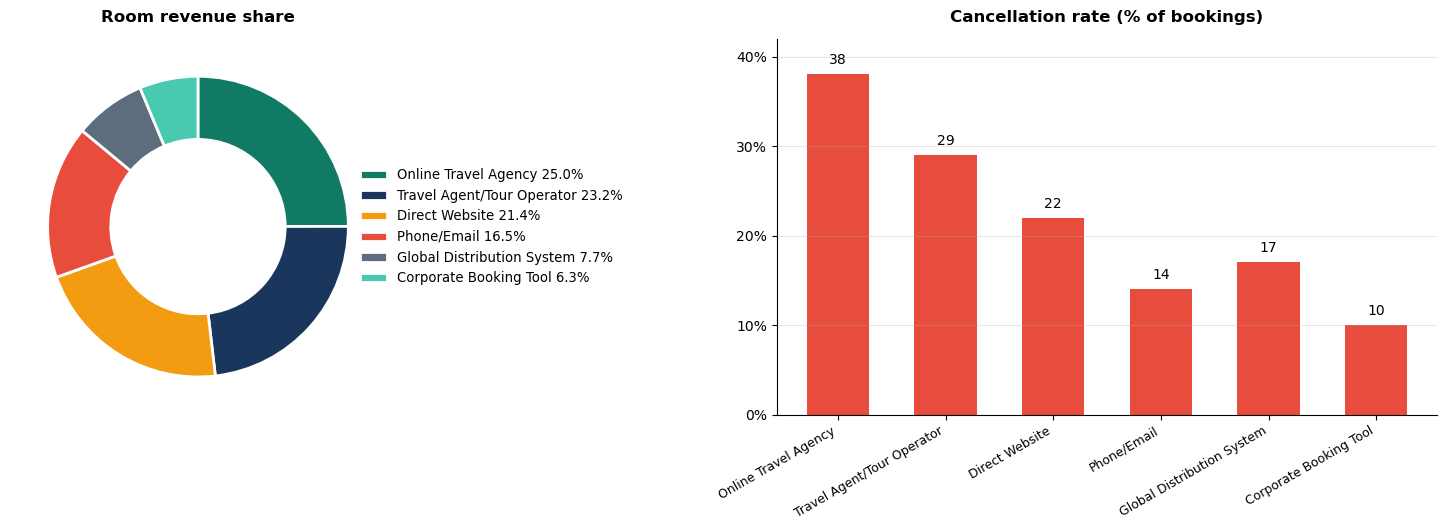

In [8]:
# --- SECTION 07: CHANNEL ANALYSIS ---

chan_order = [
    "Online Travel Agency",
    "Travel Agent/Tour Operator",
    "Direct Website",
    "Phone/Email",
    "Global Distribution System",
    "Corporate Booking Tool",
    "Front Desk"
]

tot_room_rev = nights["Room Revenue"].sum()
tot_nights = len(nights)

chan_rows = []
for ch in chan_order:
    n_ch = nights[nights["Booking Channel"] == ch]
    s_ch = stays[stays["Booking Channel"] == ch]
    all_ch = df[df["Booking Channel"] == ch]
    
    room_rev = n_ch["Room Revenue"].sum()
    tot_rev = n_ch["Total Revenue"].sum()
    paid_n = n_ch["Paid"].sum()
    
    chan_rows.append({
        "Channel": ch,
        "Room Rev Share %": round(room_rev / tot_room_rev * 100, 1),
        "Nights share": f"{len(n_ch) / tot_nights * 100:.1f}%",
        "ADR": f"€{room_rev / paid_n:.0f}" if paid_n > 0 else "n/a",
        "Cancel Rate %": round((all_ch["Cancellation Status"] == "Cancelled").mean() * 100, 1),
        "Median lead": f"{int(s_ch['Lead Time'].median())} days",
        "Ancillary %": f"{(tot_rev - room_rev) / tot_rev * 100:.1f}%" if tot_rev > 0 else "0.0%"
    })

chan_df = pd.DataFrame(chan_rows)

print("=== 07. CHANNEL ANALYSIS TABLE (SLIDE 9) ===")
print(chan_df[["Channel", "Nights share", "ADR", "Median lead", "Ancillary %", "Room Rev Share %", "Cancel Rate %"]].to_string(index=False))

# Plot Side-by-Side Charts (Excluding Front Desk, which has 0% room revenue & 0% cancellation)
plot_ch = chan_df[chan_df["Channel"] != "Front Desk"].copy()

fig, axes = plt.subplots(1, 2, figsize=(16, 5.4))

# Chart 1: Room revenue share (Donut Chart)
donut_colors = ["#117A65", "#1B365D", "#F39C12", "#E74C3C", "#5D6D7E", "#48C9B0"]
legend_labels = [f"{row['Channel']} {row['Room Rev Share %']:.1f}%" for _, row in plot_ch.iterrows()]

wedges, _ = axes[0].pie(
    plot_ch["Room Rev Share %"],
    startangle=90,
    counterclock=False,
    colors=donut_colors,
    wedgeprops=dict(width=0.42, edgecolor="white", linewidth=2)
)
axes[0].set_title("Room revenue share", fontsize=12, fontweight="bold", pad=12)
axes[0].legend(wedges, legend_labels, loc="center left", bbox_to_anchor=(0.90, 0.5), frameon=False, fontsize=9.5)

# Chart 2: Cancellation rate (% of bookings)
x = np.arange(len(plot_ch))
cancel_rounded = plot_ch["Cancel Rate %"].round(0)
bars = axes[1].bar(x, cancel_rounded, color="#E74C3C", width=0.58)

axes[1].set_title("Cancellation rate (% of bookings)", fontsize=12, fontweight="bold", pad=12)
axes[1].set_xticks(x)
axes[1].set_xticklabels(plot_ch["Channel"], fontsize=9, rotation=30, ha="right")
axes[1].set_ylim(0, 42)
axes[1].set_yticks(range(0, 41, 10))
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{int(y)}%"))
axes[1].grid(axis="y", linestyle="-", alpha=0.3)
axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)

for bar, val in zip(bars, cancel_rounded):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2, val + 0.8,
        f"{int(val)}", ha="center", va="bottom", fontsize=10
    )

plt.tight_layout()
plt.show()

=== 08A. TOTAL HOTEL KPIs PER AVAILABLE ROOM (€) ===
                   City Hotel  Resort Hotel  Portfolio
RevPAR (€)               74.3          89.4       82.2
TRevPAR (€)             101.2         153.0      128.3
GOPPAR (€)               33.0          39.3       36.3
Ancillary PAR (€)        26.9          63.6       46.1

=== 08B. MONTHLY PORTFOLIO TREVPAR VS. REVPAR (€) ===
              Jan   Feb    Mar    Apr    May    Jun    Jul    Aug    Sep  \
TRevPAR (€)  81.3  90.6  124.0  131.6  148.8  150.7  153.1  146.9  152.2   
RevPAR (€)   50.2  55.6   79.3   83.8   94.7   99.3   99.1   94.3   98.1   

               Oct    Nov    Dec  
TRevPAR (€)  136.3  105.9  115.9  
RevPAR (€)    87.8   69.1   73.3  


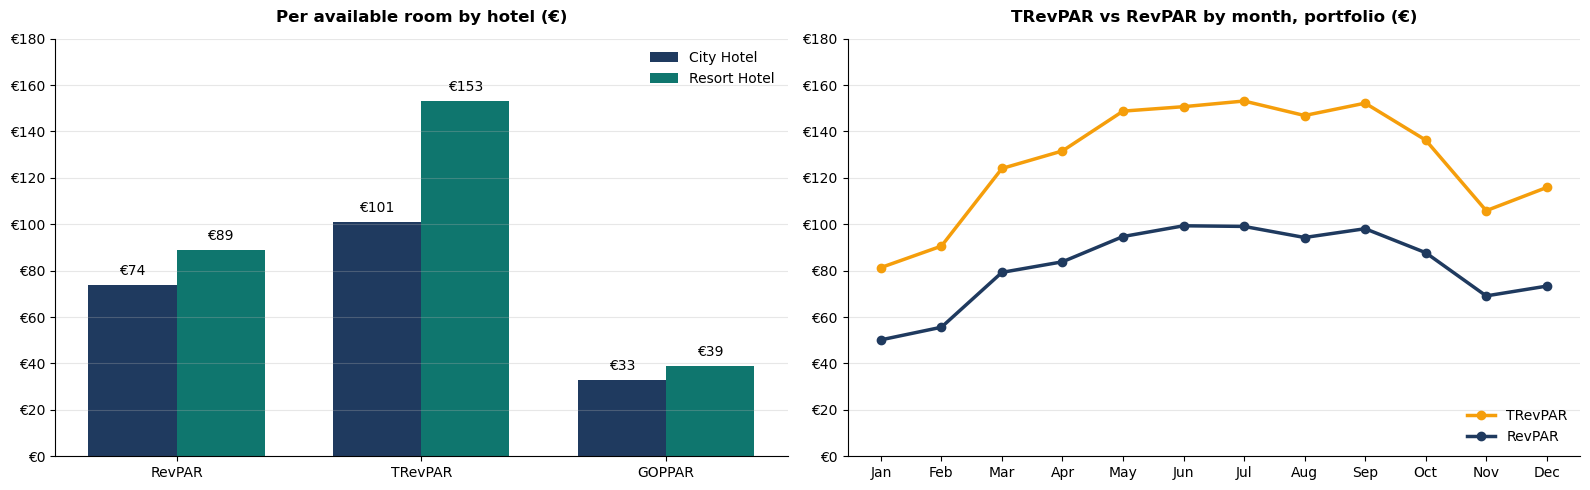

In [10]:
# --- SECTION 08: TOTAL HOTEL KPIs (EXACT REPORT COLORS) ---

def compute_total_hotel_kpis(n_df, rooms_count):
    avail = rooms_count * 365
    r_rev = n_df["Room Revenue"].sum()
    fb_rev = (n_df["Restaurant Revenue"] + n_df["Bar Revenue"]).sum()
    s_rev = n_df["Spa Revenue"].sum()
    m_rev = n_df["Meeting/Event Revenue"].sum()
    o_rev = n_df["Other Revenue"].sum()
    t_rev = r_rev + fb_rev + s_rev + m_rev + o_rev
    
    dept_profit = (
        r_rev * MARGIN["Rooms"]
        + fb_rev * MARGIN["F&B"]
        + s_rev * MARGIN["Spa"]
        + m_rev * MARGIN["Meetings"]
        + o_rev * MARGIN["Other"]
    )
    gop = dept_profit - (UNDISTRIBUTED * t_rev)
    
    return {
        "RevPAR (€)": round(r_rev / avail, 1),
        "TRevPAR (€)": round(t_rev / avail, 1),
        "GOPPAR (€)": round(gop / avail, 1),
        "Ancillary PAR (€)": round((t_rev - r_rev) / avail, 1)
    }

# 1. Per-Available-Room Comparison Table (City, Resort, Portfolio)
total_kpi_df = pd.DataFrame({
    "City Hotel": compute_total_hotel_kpis(nights[nights["Hotel"] == "City Hotel"], ROOMS["City Hotel"]),
    "Resort Hotel": compute_total_hotel_kpis(nights[nights["Hotel"] == "Resort Hotel"], ROOMS["Resort Hotel"]),
    "Portfolio": compute_total_hotel_kpis(nights, PORTFOLIO_ROOMS)
})

print("=== 08A. TOTAL HOTEL KPIs PER AVAILABLE ROOM (€) ===")
print(total_kpi_df)

# 2. Monthly Portfolio TRevPAR vs. RevPAR Pivot Table
days_in_month = (
    pd.Series(pd.date_range("2025-01-01", "2025-12-31"))
    .dt.month.value_counts()
    .sort_index()
)
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

m_avail_port = days_in_month * PORTFOLIO_ROOMS
m_r_rev = nights.groupby("Night_Month")["Room Revenue"].sum()
m_t_rev = nights.groupby("Night_Month")["Total Revenue"].sum()

monthly_port_par = pd.DataFrame({
    "TRevPAR (€)": m_t_rev / m_avail_port,
    "RevPAR (€)": m_r_rev / m_avail_port
})
monthly_port_par.index = month_names

print("\n=== 08B. MONTHLY PORTFOLIO TREVPAR VS. REVPAR (€) ===")
print(monthly_port_par.round(1).T)

# 3. Plot Side-by-Side Charts with Exact Slide 10 Colors
fig, axes = plt.subplots(1, 2, figsize=(16, 5.0))

# Chart 1: Per available room by hotel (€) (Grouped Bar Chart)
metrics_order = ["RevPAR (€)", "TRevPAR (€)", "GOPPAR (€)"]
x = np.arange(len(metrics_order))
width = 0.36

city_bars_val = total_kpi_df.loc[metrics_order, "City Hotel"].round(0)
resort_bars_val = total_kpi_df.loc[metrics_order, "Resort Hotel"].round(0)

bars_c = axes[0].bar(x - width/2, city_bars_val, width, label="City Hotel", color="#1F3A5F")
bars_r = axes[0].bar(x + width/2, resort_bars_val, width, label="Resort Hotel", color="#0F766E")

axes[0].set_title("Per available room by hotel (€)", fontsize=12, fontweight="bold", pad=12)
axes[0].set_xticks(x)
axes[0].set_xticklabels(["RevPAR", "TRevPAR", "GOPPAR"], fontsize=10)
axes[0].set_ylim(0, 180)
axes[0].set_yticks(range(0, 181, 20))
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"€{int(y)}"))
axes[0].grid(axis="y", linestyle="-", alpha=0.3)
axes[0].spines["top"].set_visible(False)
axes[0].spines["right"].set_visible(False)
axes[0].legend(frameon=False, loc="upper right")

for bars in [bars_c, bars_r]:
    for bar in bars:
        h = bar.get_height()
        axes[0].text(
            bar.get_x() + bar.get_width() / 2, h + 3,
            f"€{int(h)}", ha="center", va="bottom", fontsize=10
        )

# Chart 2: TRevPAR vs RevPAR by month, portfolio (€) — Amber/Gold (#F59E0B) & Dark Navy (#1F3A5F)
axes[1].plot(
    monthly_port_par.index, monthly_port_par["TRevPAR (€)"],
    marker="o", linewidth=2.5, markersize=6,
    color="#F59E0B", label="TRevPAR"
)
axes[1].plot(
    monthly_port_par.index, monthly_port_par["RevPAR (€)"],
    marker="o", linewidth=2.5, markersize=6,
    color="#1F3A5F", label="RevPAR"
)
axes[1].set_title("TRevPAR vs RevPAR by month, portfolio (€)", fontsize=12, fontweight="bold", pad=12)
axes[1].set_ylim(0, 180)
axes[1].set_yticks(range(0, 181, 20))
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"€{int(y)}"))
axes[1].grid(axis="y", linestyle="-", alpha=0.3)
axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)
axes[1].legend(frameon=False, loc="lower right")

plt.tight_layout()
plt.show()

=== 09A. REVENUE MIX BY DEPARTMENT & ANCILLARY CONTRIBUTION ===
                              City Hotel  Resort Hotel  Portfolio
Rooms                               73.5          58.4       64.1
Food & Beverage                     14.9          31.6       25.3
Spa                                  2.5           5.0        4.1
Meetings & Events                    4.9           2.2        3.2
Other                                4.3           2.8        3.3
Ancillary Share %                   26.5          41.6       35.9
Ancillary per Room Night (€)        40.8          94.3       69.1

=== 09B. ANCILLARY SHARE OF REVENUE BY SEGMENT (%) ===
           Segment  Ancillary Share %
           Leisure               36.7
     Tour Operator               41.1
Business Transient               19.9
             Group               47.3
Corporate Contract               23.8


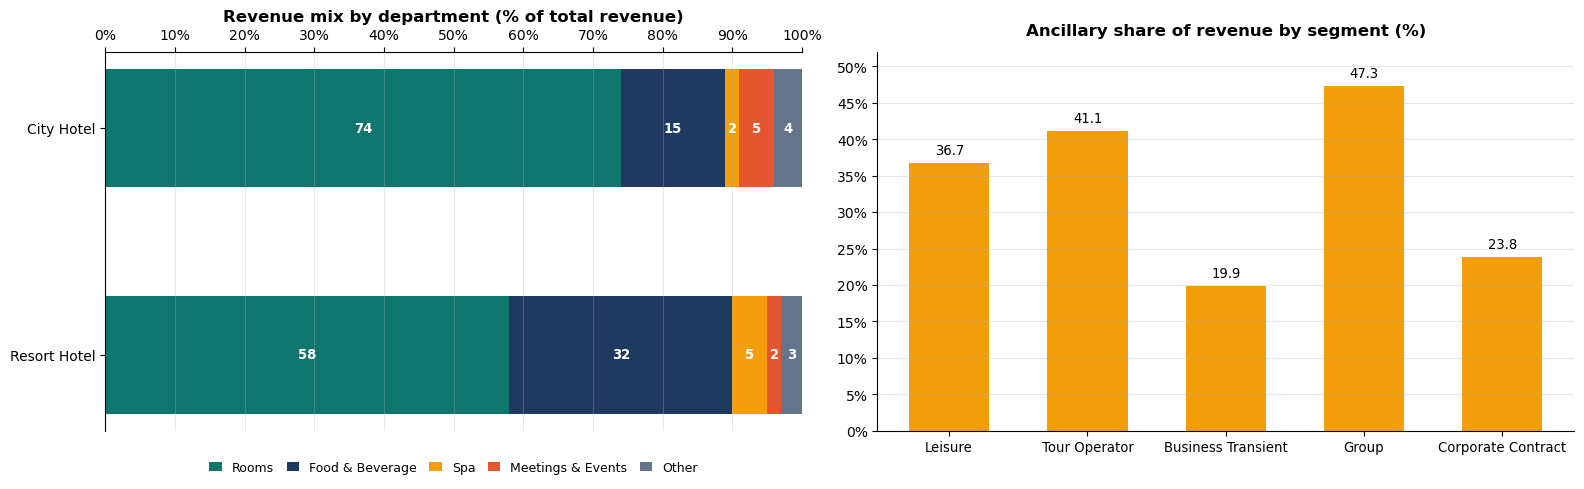

In [11]:
# --- SECTION 09: REVENUE MIX & ANCILLARY CONTRIBUTION ---

nights["F&B Revenue"] = nights["Restaurant Revenue"] + nights["Bar Revenue"]

dept_cols = ["Room Revenue", "F&B Revenue", "Spa Revenue", "Meeting/Event Revenue", "Other Revenue"]
dept_labels = ["Rooms", "Food & Beverage", "Spa", "Meetings & Events", "Other"]

# 1. Revenue Mix & Ancillary Contribution Table
mix_data = {}
for name, sub in [
    ("City Hotel", nights[nights["Hotel"] == "City Hotel"]),
    ("Resort Hotel", nights[nights["Hotel"] == "Resort Hotel"]),
    ("Portfolio", nights)
]:
    tot_rev = sub["Total Revenue"].sum()
    anc_rev = tot_rev - sub["Room Revenue"].sum()
    row_dict = {
        lbl: round(sub[col].sum() / tot_rev * 100, 1)
        for col, lbl in zip(dept_cols, dept_labels)
    }
    row_dict["Ancillary Share %"] = round(anc_rev / tot_rev * 100, 1)
    row_dict["Ancillary per Room Night (€)"] = round(anc_rev / len(sub), 1)
    mix_data[name] = row_dict

rev_mix_df = pd.DataFrame(mix_data)

print("=== 09A. REVENUE MIX BY DEPARTMENT & ANCILLARY CONTRIBUTION ===")
print(rev_mix_df)

# 2. Ancillary Share of Revenue by Market Segment (%)
seg_order_anc = ["Leisure", "Tour Operator", "Business Transient", "Group", "Corporate Contract"]
seg_anc_rows = []
for seg in seg_order_anc:
    sub = nights[nights["Market Segment"] == seg]
    tot_rev = sub["Total Revenue"].sum()
    anc_share = (tot_rev - sub["Room Revenue"].sum()) / tot_rev * 100
    seg_anc_rows.append({"Segment": seg, "Ancillary Share %": round(anc_share, 1)})

seg_anc_df = pd.DataFrame(seg_anc_rows)

print("\n=== 09B. ANCILLARY SHARE OF REVENUE BY SEGMENT (%) ===")
print(seg_anc_df.to_string(index=False))

# 3. Plot Side-by-Side Charts (Exact Slide 11 Colors)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.0))

# Chart 1: Revenue mix by department (% of total revenue) — Horizontal 100% Stacked Bar
hotels_y = ["Resort Hotel", "City Hotel"]  # Bottom-to-top so City Hotel appears on top
dept_colors = {
    "Rooms": "#0F766E",
    "Food & Beverage": "#1F3A5F",
    "Spa": "#F59E0B",
    "Meetings & Events": "#E4572E",
    "Other": "#64748B"
}

# Rounded integer shares matching Slide 11 labels (City: 73, 15, 3, 5, 4 | Resort: 58, 32, 5, 2, 3)
rounded_mix = pd.DataFrame({
    h: rev_mix_df.loc[dept_labels, h].round(0).astype(int)
    for h in hotels_y
}).T

left_cum = np.zeros(len(hotels_y))
for dept in dept_labels:
    vals = rounded_mix[dept].values
    bars = axes[0].barh(
        hotels_y, vals, left=left_cum, height=0.52,
        color=dept_colors[dept], label=dept
    )
    for i, val in enumerate(vals):
        axes[0].text(
            left_cum[i] + val / 2, i,
            f"{val}", ha="center", va="center",
            color="white", fontsize=9.5, fontweight="bold"
        )
    left_cum += vals

axes[0].set_title("Revenue mix by department (% of total revenue)", fontsize=12, fontweight="bold", pad=22)
axes[0].set_xlim(0, 100)
axes[0].set_xticks(range(0, 101, 10))
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x)}%"))
axes[0].xaxis.tick_top()
axes[0].grid(axis="x", linestyle="-", alpha=0.3)
axes[0].spines["bottom"].set_visible(False)
axes[0].spines["right"].set_visible(False)
axes[0].legend(
    loc="upper center", bbox_to_anchor=(0.5, -0.05),
    ncol=5, frameon=False, fontsize=9, handlelength=1.0, columnspacing=1.0
)

# Chart 2: Ancillary share of revenue by segment (%)
x = np.arange(len(seg_anc_df))
bars2 = axes[1].bar(x, seg_anc_df["Ancillary Share %"], color="#F59E0B", width=0.58)

axes[1].set_title("Ancillary share of revenue by segment (%)", fontsize=12, fontweight="bold", pad=12)
axes[1].set_xticks(x)
axes[1].set_xticklabels(seg_anc_df["Segment"], fontsize=9.5)
axes[1].set_ylim(0, 52)
axes[1].set_yticks(range(0, 51, 5))
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{int(y)}%"))
axes[1].grid(axis="y", linestyle="-", alpha=0.3)
axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)

for bar, val in zip(bars2, seg_anc_df["Ancillary Share %"]):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2, val + 0.8,
        f"{val:.1f}", ha="center", va="bottom", fontsize=9.5
    )

plt.tight_layout()
plt.show()

=== 10A. F&B AND SPA PER GUEST NIGHT & PENETRATION ===
              Guest Nights  F&B per guest night (€)  Spa per guest night (€)  \
Property                                                                       
City Hotel           23676                     13.9                      2.4   
Resort Hotel         42138                     27.6                      4.4   
Portfolio            65814                     22.7                      3.7   

              Spa penetration (%)  Half/Full Board share (%)  
Property                                                      
City Hotel                    7.8                        4.8  
Resort Hotel                 29.1                       49.8  
Portfolio                    16.3                       22.8  

=== 10B. MONTHLY F&B REVENUE PER GUEST NIGHT (€) ===
               Jan   Feb   Mar   Apr   May   Jun   Jul   Aug   Sep   Oct  \
Hotel                                                                      
City Hotel    14.3  14.

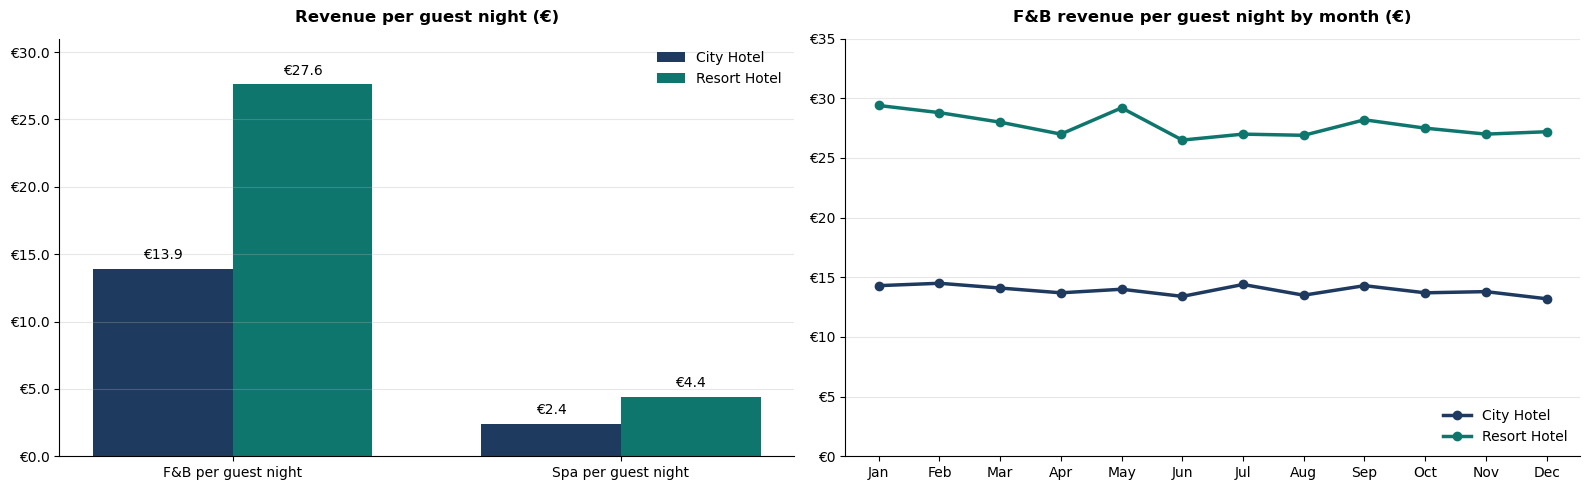

In [12]:
# --- SECTION 10: F&B AND SPA REVENUE PER GUEST ---

nights["F&B Revenue"] = nights["Restaurant Revenue"] + nights["Bar Revenue"]

# 1. Guest Night Spend, Spa Penetration & Meal Plan Summary Table
guest_rows = []
for name, n_sub, s_sub in [
    ("City Hotel", nights[nights["Hotel"] == "City Hotel"], stays[stays["Hotel"] == "City Hotel"]),
    ("Resort Hotel", nights[nights["Hotel"] == "Resort Hotel"], stays[stays["Hotel"] == "Resort Hotel"]),
    ("Portfolio", nights, stays)
]:
    gn = n_sub["Total Guests"].sum()
    fb_gn = n_sub["F&B Revenue"].sum() / gn
    spa_gn = n_sub["Spa Revenue"].sum() / gn
    spa_pen = (s_sub["Spa Revenue"] > 0).mean() * 100
    hb_fb_share = s_sub["Meal Plan"].isin(["Half Board", "Full Board"]).mean() * 100
    
    guest_rows.append({
        "Property": name,
        "Guest Nights": gn,
        "F&B per guest night (€)": round(fb_gn, 1),
        "Spa per guest night (€)": round(spa_gn, 1),
        "Spa penetration (%)": round(spa_pen, 1),
        "Half/Full Board share (%)": round(hb_fb_share, 1)
    })

guest_summary_df = pd.DataFrame(guest_rows).set_index("Property")

print("=== 10A. F&B AND SPA PER GUEST NIGHT & PENETRATION ===")
print(guest_summary_df)

# 2. Monthly F&B Revenue per Guest Night (€) Pivot Table
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
m_fb_rev = nights.groupby(["Night_Month", "Hotel"])["F&B Revenue"].sum().unstack()
m_guest_nights = nights.groupby(["Night_Month", "Hotel"])["Total Guests"].sum().unstack()

m_fb_per_gn = (m_fb_rev / m_guest_nights).round(1)
m_fb_per_gn.index = month_names

print("\n=== 10B. MONTHLY F&B REVENUE PER GUEST NIGHT (€) ===")
print(m_fb_per_gn.T)

# 3. Plot Side-by-Side Charts (Exact Slide 12 Colors)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.0))
colors = {"City Hotel": "#1F3A5F", "Resort Hotel": "#0F766E"}

# Chart 1: Revenue per guest night (€) (Grouped Bar Chart)
categories = ["F&B per guest night", "Spa per guest night"]
x = np.arange(len(categories))
width = 0.36

city_vals = [
    guest_summary_df.loc["City Hotel", "F&B per guest night (€)"],
    guest_summary_df.loc["City Hotel", "Spa per guest night (€)"]
]
resort_vals = [
    guest_summary_df.loc["Resort Hotel", "F&B per guest night (€)"],
    guest_summary_df.loc["Resort Hotel", "Spa per guest night (€)"]
]

bars_c = axes[0].bar(x - width/2, city_vals, width, label="City Hotel", color=colors["City Hotel"])
bars_r = axes[0].bar(x + width/2, resort_vals, width, label="Resort Hotel", color=colors["Resort Hotel"])

axes[0].set_title("Revenue per guest night (€)", fontsize=12, fontweight="bold", pad=12)
axes[0].set_xticks(x)
axes[0].set_xticklabels(categories, fontsize=10)
axes[0].set_ylim(0, 31)
axes[0].set_yticks(np.arange(0, 31, 5.0))
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"€{y:.1f}"))
axes[0].grid(axis="y", linestyle="-", alpha=0.3)
axes[0].spines["top"].set_visible(False)
axes[0].spines["right"].set_visible(False)
axes[0].legend(frameon=False, loc="upper right")

for bars in [bars_c, bars_r]:
    for bar in bars:
        h = bar.get_height()
        axes[0].text(
            bar.get_x() + bar.get_width() / 2, h + 0.5,
            f"€{h:.1f}", ha="center", va="bottom", fontsize=10
        )

# Chart 2: F&B revenue per guest night by month (€)
for hotel in ["City Hotel", "Resort Hotel"]:
    axes[1].plot(
        m_fb_per_gn.index, m_fb_per_gn[hotel],
        marker="o", linewidth=2.5, markersize=6,
        color=colors[hotel], label=hotel
    )
axes[1].set_title("F&B revenue per guest night by month (€)", fontsize=12, fontweight="bold", pad=12)
axes[1].set_ylim(0, 35)
axes[1].set_yticks(range(0, 36, 5))
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"€{int(y)}"))
axes[1].grid(axis="y", linestyle="-", alpha=0.3)
axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)
axes[1].legend(frameon=False, loc="lower right")

plt.tight_layout()
plt.show()

=== 11A. MEETINGS & EVENTS REVENUE SUMMARY ===
              M&E Revenue (€)  M&E Revenue (€k)  Share of Total Revenue (%)
Property                                                                   
City Hotel          108823.51             109.0                         4.9
Resort Hotel         81443.78              81.0                         2.2
Portfolio           190267.29             190.0                         3.2

=== 11B. MONTHLY MEETINGS & EVENTS REVENUE (€ THOUSAND) ===
              Jan   Feb   Mar   Apr   May   Jun   Jul   Aug   Sep   Oct   Nov  \
Hotel                                                                           
City Hotel    5.8   9.9  15.5   7.7  10.4   9.3   8.5   4.8   4.5  14.7  13.5   
Resort Hotel  0.2   3.5   0.6  14.1   6.7   4.3  14.4  10.7  13.0  10.6   2.1   
Total (€k)    6.1  13.4  16.1  21.7  17.1  13.6  22.9  15.5  17.5  25.3  15.5   

              Dec  
Hotel              
City Hotel    4.3  
Resort Hotel  1.2  
Total (€k)    5.5  

=== 1

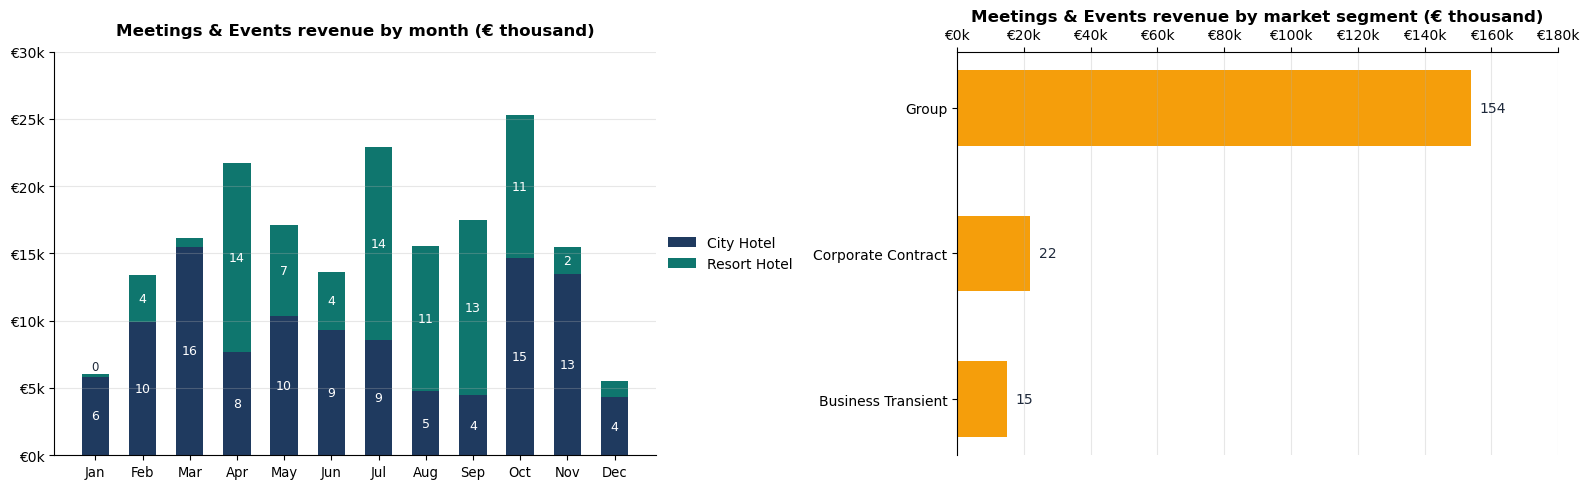

In [13]:
# --- SECTION 11: MEETINGS AND EVENTS REVENUE ---

# 1. Summary Table by Property & Portfolio
me_rows = []
for name, sub in [
    ("City Hotel", nights[nights["Hotel"] == "City Hotel"]),
    ("Resort Hotel", nights[nights["Hotel"] == "Resort Hotel"]),
    ("Portfolio", nights)
]:
    me_rev = sub["Meeting/Event Revenue"].sum()
    tot_rev = sub["Total Revenue"].sum()
    me_rows.append({
        "Property": name,
        "M&E Revenue (€)": round(me_rev, 2),
        "M&E Revenue (€k)": round(me_rev / 1000, 0),
        "Share of Total Revenue (%)": round(me_rev / tot_rev * 100, 1)
    })

me_summary_df = pd.DataFrame(me_rows).set_index("Property")
print("=== 11A. MEETINGS & EVENTS REVENUE SUMMARY ===")
print(me_summary_df)

# 2. Monthly Meetings & Events Revenue (€ thousand) Pivot Table
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
m_me_k = (
    nights.groupby(["Night_Month", "Hotel"])["Meeting/Event Revenue"].sum().unstack() / 1000.0
)
m_me_k.index = month_names
m_me_k["Total (€k)"] = m_me_k.sum(axis=1)

print("\n=== 11B. MONTHLY MEETINGS & EVENTS REVENUE (€ THOUSAND) ===")
print(m_me_k.round(1).T)

# 3. Meetings & Events Revenue by Market Segment (€ thousand)
seg_me = nights.groupby("Market Segment")["Meeting/Event Revenue"].sum()
seg_me = seg_me[seg_me > 0].sort_values(ascending=False)
tot_me = seg_me.sum()

seg_me_df = pd.DataFrame({
    "Market Segment": seg_me.index,
    "M&E Revenue (€k)": (seg_me.values / 1000.0).round(0),
    "Share of M&E (%)": (seg_me.values / tot_me * 100).round(1)
})

print("\n=== 11C. MEETINGS & EVENTS REVENUE BY MARKET SEGMENT ===")
print(seg_me_df.to_string(index=False))

# 4. Plot Side-by-Side Charts (Exact Slide 13 Colors)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.0))

# Chart 1: Meetings & Events revenue by month (€ thousand) — Stacked Bar Chart
x = np.arange(len(month_names))
city_m_vals = m_me_k["City Hotel"].values
resort_m_vals = m_me_k["Resort Hotel"].values

bars_c = axes[0].bar(x, city_m_vals, width=0.58, color="#1F3A5F", label="City Hotel")
bars_r = axes[0].bar(x, resort_m_vals, width=0.58, bottom=city_m_vals, color="#0F766E", label="Resort Hotel")

axes[0].set_title("Meetings & Events revenue by month (€ thousand)", fontsize=12, fontweight="bold", pad=12)
axes[0].set_xticks(x)
axes[0].set_xticklabels(month_names, fontsize=9.5)
axes[0].set_ylim(0, 30)
axes[0].set_yticks(range(0, 31, 5))
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"€{int(y)}k"))
axes[0].grid(axis="y", linestyle="-", alpha=0.3)
axes[0].spines["top"].set_visible(False)
axes[0].spines["right"].set_visible(False)
axes[0].legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5))

for i in range(len(month_names)):
    c_rnd = int(round(city_m_vals[i]))
    r_rnd = int(round(resort_m_vals[i]))
    if city_m_vals[i] > 1.2:
        axes[0].text(
            x[i], city_m_vals[i] / 2, f"{c_rnd}",
            ha="center", va="center", color="white", fontsize=9
        )
    if resort_m_vals[i] > 1.2:
        axes[0].text(
            x[i], city_m_vals[i] + resort_m_vals[i] / 2, f"{r_rnd}",
            ha="center", va="center", color="white", fontsize=9
        )
    elif r_rnd == 0 and resort_m_vals[i] > 0:
        axes[0].text(
            x[i], city_m_vals[i] + 0.3, "0",
            ha="center", va="bottom", color="#1E293B", fontsize=8.5
        )

# Chart 2: Meetings & Events revenue by market segment (€ thousand) — Horizontal Bar Chart
seg_plot = seg_me_df.iloc[::-1]  # Reverse order so Group appears at the top
y_pos = np.arange(len(seg_plot))
bars_h = axes[1].barh(y_pos, seg_plot["M&E Revenue (€k)"], height=0.52, color="#F59E0B")

axes[1].set_title("Meetings & Events revenue by market segment (€ thousand)", fontsize=12, fontweight="bold", pad=22)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(seg_plot["Market Segment"], fontsize=10)
axes[1].set_xlim(0, 180)
axes[1].set_xticks(range(0, 181, 20))
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda val, _: f"€{int(val)}k"))
axes[1].xaxis.tick_top()
axes[1].grid(axis="x", linestyle="-", alpha=0.3)
axes[1].spines["bottom"].set_visible(False)
axes[1].spines["right"].set_visible(False)

for bar, val in zip(bars_h, seg_plot["M&E Revenue (€k)"]):
    axes[1].text(
        val + 2.5, bar.get_y() + bar.get_height() / 2,
        f"{int(val)}", ha="left", va="center", fontsize=10, color="#1E293B"
    )

plt.tight_layout()
plt.show()

=== 12A. DEPARTMENTAL PROFIT BY HOTEL (€ THOUSAND) ===
                   City Hotel  Resort Hotel  Portfolio
Rooms                  1172.0        1550.0     2722.0
Food & Beverage          99.0         349.0      448.0
Spa                      20.0          65.0       84.0
Meetings & Events        49.0          37.0       86.0
Other                    47.0          51.0       98.0

Rooms share of Portfolio departmental profit: 79.2%

=== 12B. P&L SUMMARY TABLE (SLIDE 14) ===
Property               City Hotel Resort Hotel Portfolio
Total revenue              €2.22M       €3.69M    €5.90M
Departmental profit        €1.39M       €2.05M    €3.44M
Undistributed expenses     €0.66M       €1.11M    €1.77M
Gross operating profit     €0.72M       €0.95M    €1.67M
GOP margin                  32.6%        25.7%     28.3%
GOPPAR                      €33.0        €39.3     €36.3


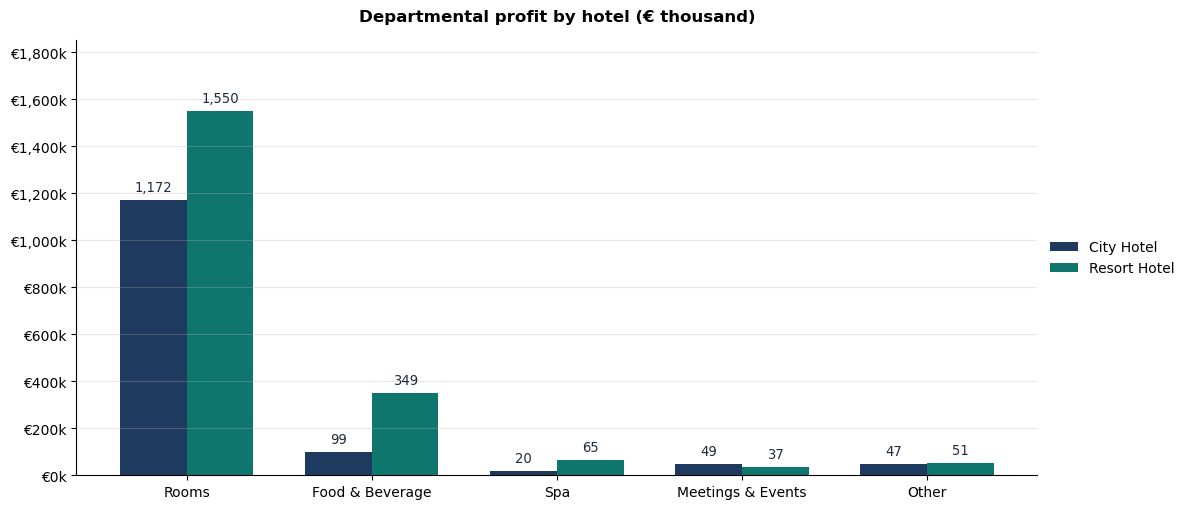

In [14]:
# --- SECTION 12: PROFITABILITY BY DEPARTMENT ---

nights["F&B Revenue"] = nights["Restaurant Revenue"] + nights["Bar Revenue"]

dept_cols = ["Room Revenue", "F&B Revenue", "Spa Revenue", "Meeting/Event Revenue", "Other Revenue"]
dept_names = ["Rooms", "Food & Beverage", "Spa", "Meetings & Events", "Other"]
margin_vals = [
    MARGIN["Rooms"],
    MARGIN["F&B"],
    MARGIN["Spa"],
    MARGIN["Meetings"],
    MARGIN["Other"]
]

# 1. Departmental Profit (€ thousand) Table
dept_prof_data = {}
for name, sub in [
    ("City Hotel", nights[nights["Hotel"] == "City Hotel"]),
    ("Resort Hotel", nights[nights["Hotel"] == "Resort Hotel"]),
    ("Portfolio", nights)
]:
    dept_prof_data[name] = {
        d_name: round(sub[col].sum() * m / 1000.0, 0)
        for col, d_name, m in zip(dept_cols, dept_names, margin_vals)
    }

dept_prof_df = pd.DataFrame(dept_prof_data)
rooms_prof_share = dept_prof_df.loc["Rooms", "Portfolio"] / dept_prof_df["Portfolio"].sum() * 100

print("=== 12A. DEPARTMENTAL PROFIT BY HOTEL (€ THOUSAND) ===")
print(dept_prof_df)
print(f"\nRooms share of Portfolio departmental profit: {rooms_prof_share:.1f}%")

# 2. Full P&L Summary Table (Slide 14)
pnl_rows = []
for name, sub, r_cnt in [
    ("City Hotel", nights[nights["Hotel"] == "City Hotel"], ROOMS["City Hotel"]),
    ("Resort Hotel", nights[nights["Hotel"] == "Resort Hotel"], ROOMS["Resort Hotel"]),
    ("Portfolio", nights, PORTFOLIO_ROOMS)
]:
    tot_rev = sub["Total Revenue"].sum()
    dept_prof = sum(sub[col].sum() * m for col, m in zip(dept_cols, margin_vals))
    undist = tot_rev * UNDISTRIBUTED
    gop = dept_prof - undist
    avail = r_cnt * 365
    
    pnl_rows.append({
        "Property": name,
        "Total revenue": f"€{tot_rev / 1e6:.2f}M",
        "Departmental profit": f"€{dept_prof / 1e6:.2f}M",
        "Undistributed expenses": f"€{undist / 1e6:.2f}M",
        "Gross operating profit": f"€{gop / 1e6:.2f}M",
        "GOP margin": f"{gop / tot_rev * 100:.1f}%",
        "GOPPAR": f"€{gop / avail:.1f}"
    })

pnl_summary_df = pd.DataFrame(pnl_rows).set_index("Property").T

print("\n=== 12B. P&L SUMMARY TABLE (SLIDE 14) ===")
print(pnl_summary_df)

# 3. Plot Grouped Bar Chart: Departmental profit by hotel (€ thousand)
fig, ax = plt.subplots(figsize=(12, 5.2))

x = np.arange(len(dept_names))
width = 0.36

city_vals = dept_prof_df["City Hotel"].values
resort_vals = dept_prof_df["Resort Hotel"].values

bars_c = ax.bar(x - width/2, city_vals, width, label="City Hotel", color="#1F3A5F")
bars_r = ax.bar(x + width/2, resort_vals, width, label="Resort Hotel", color="#0F766E")

ax.set_title("Departmental profit by hotel (€ thousand)", fontsize=12, fontweight="bold", pad=14)
ax.set_xticks(x)
ax.set_xticklabels(dept_names, fontsize=10)
ax.set_ylim(0, 1850)
ax.set_yticks(range(0, 1801, 200))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"€{int(y):,}k"))
ax.grid(axis="y", linestyle="-", alpha=0.3)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5))

for bars in [bars_c, bars_r]:
    for bar in bars:
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2, h + 25,
            f"{int(h):,}", ha="center", va="bottom", fontsize=9.5, color="#1E293B"
        )

plt.tight_layout()
plt.show()